# 7. LightGCN on EuroMart (quarterly) and Retail POS

For each eligible customer, LightGCN ranks the 17 categories they may buy in the next period (a quarter for EuroMart, a month for Retail POS). The model is compared with popularity and purchase-history baselines.

LightGCN is a GCN without weight matrices and without nonlinearities, so its only parameters are the node embeddings. It does not use the 7 + 7 node features; everything it knows comes from the purchase graph. The model is written in NumPy and runs on a CPU. Propagation is linear and the normalised adjacency is symmetric, so the backward pass applies the same operator, and the gradient is checked against finite differences in section 11.

The selected hyperparameters are loaded from `frozen_selection.json` (section 5 explains how to re-run the search). Tables are written to `outputs/lightgcn/`.

In [ ]:
import json, hashlib, pathlib, time, itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:                       
    import scipy.sparse as sp
    HAVE_SCIPY = True
except Exception:
    sp = None
    HAVE_SCIPY = False

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("scipy available:", HAVE_SCIPY)

scipy available: True


## 1. Setup
- Task: rank all 17 categories for each eligible customer (seen in an earlier period and active in the target period)
- Graph: all purchases before the target period, binary and undirected
- Loss: full binary cross-entropy over the 17 candidates with a shared `pos_weight`, no negative sampling
- Decoder: dot product of customer and category embeddings
- Selection: validation NDCG@10 with seeds 101-105, then frozen
- Final runs: seeds 42-51, test periods used once

Snapshots are only read here, never rebuilt. The EuroMart quarterly ones come from notebook 10.

In [2]:
SUB  = pathlib.Path.cwd()                         # .../SC4020-DataMining/Submission
REPO = SUB.parent
OUT  = SUB / "outputs" / "lightgcn"               # every table this notebook writes
OUT.mkdir(parents=True, exist_ok=True)
PUBLISHED = REPO / "results" / "nicholas lightgcn"  # committed tables, used only by the reproduction check

SNAP_DIRS = {
    "euromart_quarterly": SUB / "data" / "euromart_quarterly",               # built by notebook 10
    "retail_pos_monthly": REPO / "graph_data" / "retail_pos" / "monthly",    # team Run 2 release
    "euromart_monthly":   SUB / "data" / "euromart_monthly",                 # team Run 2 release (earlier granularity)
}
CANDIDATES = SNAP_DIRS
HEADLINE = ["euromart_quarterly", "retail_pos_monthly"]   # the two main datasets

def snap_dir(key):
    d = SNAP_DIRS.get(key)
    return d if d is not None and d.is_dir() else None

for k in CANDIDATES:
    d = snap_dir(k)
    print(f"{k:20s} {len(list(d.glob('*.npz'))) if d else 0:3d} snapshots   {d.relative_to(REPO) if d else 'missing'}")

euromart_quarterly    16 snapshots   Submission\data\euromart_quarterly
retail_pos_monthly    12 snapshots   graph_data\retail_pos\monthly
euromart_monthly      48 snapshots   Submission\data\euromart_monthly


`euromart_monthly` is the earlier granularity. It is only used for the before/after comparison in section 9b.

In [3]:
# Arrays every model and baseline here needs.
SNAP_KEYS = ["edge_index_bipartite", "customer_features", "category_features",
             "category_features_raw", "history_customer_mask", "history_category_mask",
             "customer_history_degree", "category_history_degree",
             "eligible_customer_idx", "labels",
             "eligible_history_pair_mask", "eligible_previous_month_mask",
             "eligible_history_degree"]

# Per-pair history aggregates. The newer "node only" snapshots omit these on purpose
# (the standard prohibits engineered pair attributes), so they are optional.
SNAP_OPTIONAL = ["eligible_history_interaction_count", "eligible_history_order_count",
                 "eligible_history_quantity", "eligible_history_value",
                 "eligible_history_freshness"]

def load_period(path):
    z = np.load(path, allow_pickle=True)
    d = {k: z[k] for k in SNAP_KEYS}
    for k in SNAP_OPTIONAL:
        if k in z.files:
            d[k] = z[k]
    d["n_customers"] = int(z["customer_features"].shape[0])
    d["n_categories"] = int(z["category_features"].shape[0])
    return d

In [4]:
SPLITS = {
 "euromart_quarterly": dict(
    train=["2011Q2","2011Q3","2011Q4","2012Q1","2012Q2","2012Q3","2012Q4","2013Q1","2013Q2","2013Q3"],
    val=["2013Q4","2014Q1"], test=["2014Q2","2014Q3","2014Q4"]),
 "retail_pos_monthly": dict(
    train=[f"2024-{m:02d}" for m in range(1, 9)],
    val=["2024-09","2024-10"], test=["2024-11","2024-12"]),
 "euromart_monthly": dict(
    train=[f"{y}-{m:02d}" for y in (2011, 2012) for m in range(1, 13)] + [f"2013-{m:02d}" for m in range(1, 9)],
    val=[f"2013-{m:02d}" for m in range(9, 13)] + [f"2014-{m:02d}" for m in range(1, 5)],
    test=[f"2014-{m:02d}" for m in range(5, 13)]),
}

def load_dataset(key):
    d = snap_dir(key)
    if d is None:
        return None
    out = {}
    for split, names in SPLITS[key].items():
        ps = []
        for name in names:
            p = load_period(d / f"{name}.npz")
            p["_name"], p["_split"] = name, split
            ps.append(p)
        out[split] = ps
    nc = out["train"][0]["n_customers"]; nk = out["train"][0]["n_categories"]
    y = np.concatenate([p["labels"] for p in out["train"] if p["labels"].size], axis=0)
    pos = int(y.sum()); neg = int(y.size) - pos
    out["meta"] = dict(n_customers=nc, n_categories=nk,
                       pos_weight=float(neg / pos), prevalence=float(pos / y.size))
    return out

DATASETS = {k: load_dataset(k) for k in CANDIDATES}
DATASETS = {k: v for k, v in DATASETS.items() if v is not None}

rows = []
for k, ds in DATASETS.items():
    m = ds["meta"]
    rows.append(dict(dataset=k, customers=m["n_customers"], categories=m["n_categories"],
                     pos_weight=round(m["pos_weight"], 6), prevalence=round(m["prevalence"], 6),
                     **{s: len(ds[s]) for s in ("train", "val", "test")},
                     val_cp=sum(len(p["eligible_customer_idx"]) for p in ds["val"]),
                     test_cp=sum(len(p["eligible_customer_idx"]) for p in ds["test"]),
                     test_customers=len(np.unique(np.concatenate([p["eligible_customer_idx"] for p in ds["test"]])))))
pd.DataFrame(rows)

,dataset,customers,categories,pos_weight,prevalence,train,val,test,val_cp,test_cp,test_customers
0,euromart_quarterly,792,17,7.099659,0.123462,10,2,3,445,872,583
1,retail_pos_monthly,488,17,2.534087,0.282958,8,2,2,255,262,235
2,euromart_monthly,792,17,7.842142,0.113095,32,8,8,679,919,566


`pos_weight` matches the `loss_diagnostics.json` that comes with the snapshots (7.099659 for EuroMart quarterly, 2.534087 for Retail POS).

## 2. Model
Customers and categories in one node set, symmetric adjacency:

$$A=\begin{bmatrix}0 & R\\ R^{\top} & 0\end{bmatrix},\qquad \hat A = D^{-1/2} A D^{-1/2}$$

No self loop (the layer averaging below already keeps each node's own embedding).

No weights, no activation, average over the layers:

$$E^{(k)} = \hat A E^{(k-1)},\qquad E = \frac{1}{K+1}\sum_{k=0}^{K} E^{(k)}$$

In [5]:
class DenseAdj:
    """NumPy stand-in for a sparse matrix, used when scipy is unavailable.
    The graph is tiny (809 nodes for EuroMart), so a dense operator costs a few MB."""
    __slots__ = ("A",)
    def __init__(self, A): self.A = A
    def __matmul__(self, X): return self.A @ X
    def todense(self): return self.A

def normalised_adjacency(edge_bip, n_cust, n_cat, rng=None, rewire=False):
    n = n_cust + n_cat
    if edge_bip.shape[1] == 0:
        return sp.csr_matrix((n, n)) if HAVE_SCIPY else DenseAdj(np.zeros((n, n)))
    if rewire:
        edge_bip = double_edge_swap(edge_bip, rng)
    c = edge_bip[0].astype(np.int64)
    k = edge_bip[1].astype(np.int64)
    rows = np.concatenate([c, n_cust + k])
    cols = np.concatenate([n_cust + k, c])
    deg = np.bincount(rows, minlength=n).astype(np.float64)
    dinv = np.zeros(n); nz = deg > 0
    dinv[nz] = 1.0 / np.sqrt(deg[nz])
    vals = dinv[rows] * dinv[cols]
    if HAVE_SCIPY:
        return sp.csr_matrix((vals, (rows, cols)), shape=(n, n))
    dense = np.zeros((n, n))
    np.add.at(dense, (rows, cols), vals)      # sums duplicates, as csr_matrix does
    return DenseAdj(dense)

In [6]:
def propagate(adj, E0, K):
    """E = (1/(K+1)) * sum_{k=0..K} A_hat^k E0.

    Accumulate the raw sum and divide ONCE at the end: dividing each term before
    adding changes the float rounding and can shift the early-stopping epoch."""
    if K == 0:
        return E0.copy()
    acc = E0
    total = E0.copy()
    for _ in range(K):
        acc = adj @ acc
        total = total + acc
    return total / (K + 1)

def attach_adj(periods, n_cust, n_cat, rewire_seed=None):
    for p in periods:
        rng = seeded_rng("rewire", rewire_seed, p["_name"]) if rewire_seed is not None else None
        p["_adj"] = normalised_adjacency(p["edge_index_bipartite"], n_cust, n_cat,
                                         rng=rng, rewire=rewire_seed is not None)

### Training
Adam, one step per epoch over all training periods together (each period has its own snapshot), with gradient clipping at 5.0. Three stability gates are fixed before any run: median |logit|, 99th-percentile |logit| and gradient norm. A seed that fails a gate is logged and dropped.

In [7]:
STABILITY_GATES = dict(median_abs_logit_max=100.0, p99_abs_logit_max=250.0,
                       preclip_gradient_norm_max=1e6, postclip_gradient_norm_max=5.0001)
GRAD_CLIP = 5.0

class Adam:
    def __init__(self, shape, lr, wd, b1=0.9, b2=0.999, eps=1e-8):
        self.m = np.zeros(shape); self.v = np.zeros(shape)
        self.lr, self.wd, self.b1, self.b2, self.eps, self.t = lr, wd, b1, b2, eps, 0
    def step(self, p, g):
        self.t += 1
        g = g + self.wd * p
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * (g * g)
        mh = self.m / (1 - self.b1 ** self.t)
        vh = self.v / (1 - self.b2 ** self.t)
        return p - self.lr * mh / (np.sqrt(vh) + self.eps)

In [8]:
def loss_and_grad(E0, K, periods, pos_weight, n_cust):
    """Full BCE with pos_weight over every eligible customer-period x 17 pair.

    Because A_hat is symmetric and propagation is linear, the gradient w.r.t. E0 is
    the same propagation applied to the gradient at the output - no autodiff needed."""
    dE0 = np.zeros_like(E0)
    total, npairs, logits_all = 0.0, 0, []
    for p in periods:
        elig, Y = p["eligible_customer_idx"], p["labels"].astype(np.float64)
        if len(elig) == 0:
            continue
        E = propagate(p["_adj"], E0, K)
        S = E[elig] @ E[n_cust:].T
        logits_all.append(S.ravel())
        sig = 1.0 / (1.0 + np.exp(-np.clip(S, -60, 60)))
        w = pos_weight * Y + (1.0 - Y)
        total += float(np.sum(-(pos_weight * Y * np.log(sig + 1e-12)
                               + (1 - Y) * np.log(1 - sig + 1e-12))))
        npairs += Y.size
        G = w * sig - pos_weight * Y
        dE = np.zeros_like(E)
        np.add.at(dE, elig, G @ E[n_cust:])
        dE[n_cust:] += G.T @ E[elig]
        dE0 += propagate(p["_adj"], dE, K)
    if npairs == 0:
        return 0.0, dE0, np.zeros(0)
    return total / npairs, dE0 / npairs, np.concatenate(logits_all)

In [9]:
def stack_scores(periods, E0, K, n_cust):
    Ss, Ys = [], []
    for p in periods:
        elig = p["eligible_customer_idx"]
        if len(elig) == 0:
            continue
        E = propagate(p["_adj"], E0, K)
        Ss.append(E[elig] @ E[n_cust:].T)
        Ys.append(p["labels"])
    if not Ss:
        return np.zeros((0, 17)), np.zeros((0, 17), dtype=np.uint8)
    return np.vstack(Ss), np.vstack(Ys)

def eval_ndcg(periods, E0, K, n_cust, k=10):
    S, Y = stack_scores(periods, E0, K, n_cust)
    return ndcg_at_k(S, Y, k)

def train_lightgcn(train_p, val_p, n_cust, n_cat, pos_weight, K, dim, lr, wd,
                   seed, epochs=200, patience=20, sel_k=10):
    rng = np.random.default_rng(seed)
    E0 = rng.normal(0.0, 0.1, size=(n_cust + n_cat, dim))
    opt = Adam(E0.shape, lr, wd)
    best, best_E0, best_epoch, bad = -np.inf, E0.copy(), 0, 0
    diag = dict(max_preclip_gnorm=0.0, max_postclip_gnorm=0.0,
                median_abs_logit=0.0, p99_abs_logit=0.0, failed=False, reason="")
    for ep in range(1, epochs + 1):
        _, g, logits = loss_and_grad(E0, K, train_p, pos_weight, n_cust)
        gn = float(np.linalg.norm(g))
        diag["max_preclip_gnorm"] = max(diag["max_preclip_gnorm"], gn)
        if not np.isfinite(gn):
            diag.update(failed=True, reason="non-finite gradient"); break
        if gn > GRAD_CLIP:
            g = g * (GRAD_CLIP / gn)
        diag["max_postclip_gnorm"] = max(diag["max_postclip_gnorm"], float(np.linalg.norm(g)))
        if logits.size:
            a = np.abs(logits)
            diag["median_abs_logit"] = max(diag["median_abs_logit"], float(np.median(a)))
            diag["p99_abs_logit"] = max(diag["p99_abs_logit"], float(np.percentile(a, 99)))
        E0 = opt.step(E0, g)
        if not np.all(np.isfinite(E0)):
            diag.update(failed=True, reason="non-finite embeddings"); break
        v = eval_ndcg(val_p, E0, K, n_cust, sel_k)
        if v > best + 1e-12:
            best, best_E0, best_epoch, bad = v, E0.copy(), ep, 0
        else:
            bad += 1
            if bad >= patience:
                break
    if not diag["failed"]:
        if diag["median_abs_logit"] > STABILITY_GATES["median_abs_logit_max"]:
            diag.update(failed=True, reason="median |logit| gate")
        elif diag["p99_abs_logit"] > STABILITY_GATES["p99_abs_logit_max"]:
            diag.update(failed=True, reason="p99 |logit| gate")
        elif diag["max_postclip_gnorm"] > STABILITY_GATES["postclip_gradient_norm_max"]:
            diag.update(failed=True, reason="post-clip gradient gate")
    return best_E0, best, best_epoch, diag

## 3. Metrics
Recall, Precision, NDCG and HitRate at 3, 5 and 10, averaged over customer-periods, plus PR-AUC (micro-averaged average precision, with tied scores grouped as in scikit-learn). Ties in the ranking are broken by candidate index.

In [10]:
_LOG2 = np.log2(np.arange(2, 32))

def average_precision(score, y):
    """Micro average precision with tied scores grouped (as in scikit-learn), so the
    result does not depend on the order of tied rows, e.g. the identical scores that
    GlobalPopularity gives every customer."""
    o = np.argsort(-score, kind="stable")
    s, y = score[o], y[o].astype(np.float64)
    P = y.sum()
    if P == 0:
        return np.nan
    last = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]   # end of each block of tied scores
    tp = np.cumsum(y)[last]
    prec, rec = tp / (last + 1), tp / P
    return float(np.sum(np.diff(np.r_[0.0, rec]) * prec))

def ranking_metrics(scores, labels, ks=(3, 5, 10)):
    if scores.shape[0] == 0:
        return {f"{m}@{k}": np.nan for k in ks for m in ("Recall","Precision","NDCG","HitRate")} | {"PR-AUC": np.nan}
    order = np.argsort(-scores, axis=1, kind="stable")
    rel = np.take_along_axis(labels, order, axis=1).astype(np.float64)
    npos = labels.sum(axis=1).astype(np.float64)
    out = {}
    for k in ks:
        r = rel[:, :k]; hits = r.sum(axis=1); disc = 1.0 / _LOG2[:k]
        dcg = (r * disc).sum(axis=1)
        idcg = np.array([disc[:m].sum() if m > 0 else 1.0 for m in np.minimum(npos, k).astype(int)])
        out[f"Recall@{k}"]    = float(np.mean(np.where(npos > 0, hits / np.maximum(npos, 1), 0.0)))
        out[f"Precision@{k}"] = float(np.mean(hits / k))
        out[f"NDCG@{k}"]      = float(np.mean(np.where(idcg > 0, dcg / idcg, 0.0)))
        out[f"HitRate@{k}"]   = float(np.mean(hits > 0))
    out["PR-AUC"] = average_precision(scores.ravel(), labels.ravel())
    return out

def ndcg_at_k(scores, labels, k=10):
    """Selection metric only - skips the pooled PR-AUC cost."""
    if scores.shape[0] == 0:
        return np.nan
    idx = np.argpartition(-scores, min(k, scores.shape[1] - 1), axis=1)[:, :k]
    sub = np.take_along_axis(scores, idx, axis=1)
    top = np.take_along_axis(idx, np.argsort(-sub, axis=1, kind="stable"), axis=1)
    rel = np.take_along_axis(labels, top, axis=1).astype(np.float64)
    disc = 1.0 / _LOG2[:k]
    dcg = (rel * disc).sum(axis=1)
    npos = labels.sum(axis=1)
    idcg = np.array([disc[:m].sum() if m > 0 else 1.0 for m in np.minimum(npos, k).astype(int)])
    return float(np.mean(np.where(idcg > 0, dcg / idcg, 0.0)))

## 4. Baselines
Five heuristics score the 17 categories by rank: Random, GlobalPopularity, PersonalHistory, RepeatLastPeriod and PopularityPersonalBlend. The history-based ones use purchase counts when the snapshot has them and the binary mask otherwise (the cell prints which). Section 10 repeats the comparison with the definitions from the shared baseline run (Run 3).

In [11]:
def seeded_rng(*parts):
    h = hashlib.sha256("|".join(str(p) for p in parts).encode()).digest()
    return np.random.default_rng(int.from_bytes(h[:8], "little"))

def rank_score(*keys):
    """Rank 17..1 under a cascade of keys, most significant first."""
    R, C = keys[0].shape
    order = np.lexsort(tuple(-k for k in reversed(keys)), axis=1)
    out = np.empty((R, C), dtype=np.float64)
    np.put_along_axis(out, order, np.arange(C, 0, -1, dtype=np.float64)[None, :].repeat(R, 0), axis=1)
    return out

def popularity_key(snap):
    """Total historical interactions per category (category_features_raw column 0)."""
    return snap["category_features_raw"][:, 0].astype(np.float64)

def history_strength(snap):
    if "eligible_history_interaction_count" in snap:
        return snap["eligible_history_interaction_count"].astype(np.float64)
    return snap["eligible_history_pair_mask"].astype(np.float64)

def baseline_definition(snap):
    return "interaction count" if "eligible_history_interaction_count" in snap else "binary history mask"

BASELINES = ["Random", "GlobalPopularity", "PersonalHistory", "RepeatLastPeriod", "PopularityPersonalBlend"]

def baseline_scores(name, snap, dataset, period, seed=0):
    R = len(snap["eligible_customer_idx"]); C = snap["n_categories"]
    pop = popularity_key(snap)
    if name == "Random":
        return seeded_rng(dataset, period, name, seed).random((R, C))
    if name == "GlobalPopularity":
        return rank_score(np.tile(pop, (R, 1)))
    if name == "PersonalHistory":
        return rank_score(history_strength(snap), np.tile(pop, (R, 1)))
    if name == "RepeatLastPeriod":                       # previous period -> history -> popularity
        return rank_score(snap["eligible_previous_month_mask"].astype(np.float64),
                          history_strength(snap), np.tile(pop, (R, 1)))
    if name == "PopularityPersonalBlend":
        p = pop / (pop.max() if pop.max() > 0 else 1.0)
        ph = history_strength(snap)
        ph = ph / np.where(ph.max(axis=1, keepdims=True) > 0, ph.max(axis=1, keepdims=True), 1.0)
        return rank_score(0.5 * np.tile(p, (R, 1)) + 0.5 * ph, np.tile(pop, (R, 1)))
    raise ValueError(name)

In [12]:
def run_baselines(key, ds):
    rows, dumps = [], {}
    for name in BASELINES:
        Ss, Ys = [], []
        for p in ds["test"]:
            if len(p["eligible_customer_idx"]) == 0:
                continue
            Ss.append(baseline_scores(name, p, key, p["_name"]))
            Ys.append(p["labels"])
        S, Y = np.vstack(Ss), np.vstack(Ys)
        m = ranking_metrics(S, Y); m.update(dataset=key, method=name)
        rows.append(m); dumps[name] = S
    return pd.DataFrame(rows), dumps

BASE_DF, BASE_DUMPS = {}, {}
for key, ds in DATASETS.items():
    nc, nk = ds["meta"]["n_customers"], ds["meta"]["n_categories"]
    for s_ in ("train", "val", "test"):
        attach_adj(ds[s_], nc, nk)
    BASE_DF[key], BASE_DUMPS[key] = run_baselines(key, ds)
    print(f"{key}: personal-history signal = {baseline_definition(ds['test'][0])}")

pd.concat(BASE_DF.values()).to_csv(OUT / "baselines.csv", index=False)
pd.concat(BASE_DF.values())[["dataset","method","NDCG@5","NDCG@10","Recall@10","PR-AUC"]].round(4)

euromart_quarterly: personal-history signal = interaction count
retail_pos_monthly: personal-history signal = interaction count
euromart_monthly: personal-history signal = interaction count


,dataset,method,NDCG@5,NDCG@10,Recall@10,PR-AUC
0,euromart_quarterly,Random,0.2167,0.3300,0.5895,0.1271
1,euromart_quarterly,GlobalPopularity,0.3847,0.4773,0.7288,0.2062
2,euromart_quarterly,PersonalHistory,0.3305,0.4404,0.7152,0.1805
3,euromart_quarterly,RepeatLastPeriod,0.3233,0.4355,0.7154,0.1775
4,euromart_quarterly,PopularityPersonalBlend,0.3309,0.4411,0.7169,0.1807
0,retail_pos_monthly,Random,0.3046,0.4340,0.5813,0.2832
1,retail_pos_monthly,GlobalPopularity,0.4873,0.6291,0.7683,0.4148
2,retail_pos_monthly,PersonalHistory,0.4285,0.5713,0.7225,0.3679
3,retail_pos_monthly,RepeatLastPeriod,0.4225,0.5678,0.7221,0.3632
4,retail_pos_monthly,PopularityPersonalBlend,0.4291,0.5730,0.7255,0.3688


GlobalPopularity scores 0.4773 NDCG@10 on EuroMart and 0.6291 on Retail POS, identical to the shared Run 3 results, so the evaluation code agrees. With 17 candidates and 12-29% positives, popularity is already a strong baseline.

## 5. Selection
Two versions of LightGCN are selected on validation NDCG@10 (seeds 101-105); the test periods are not used:
- **Controlled**: shared defaults (64-d, learning rate 1e-3, weight decay 1e-5), only the depth K searched (1-3)
- **Tuned**: 240 configurations over K, embedding size, learning rate and weight decay

The selected settings are loaded from `frozen_selection.json`. Set `RUN_FULL_SEARCH = True` to re-run both searches (about an hour on a CPU).

In [13]:
SELECTION_SEEDS = [101, 102, 103, 104, 105]
FINAL_SEEDS     = [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]
LEGACY_SEEDS    = [42, 43, 44]
CONTRACT        = dict(dim=64, lr=1e-3, wd=1e-5)
SEARCH = dict(epochs=100, patience=12)     # search budget
FINAL  = dict(epochs=200, patience=20)     # final budget

RUN_FULL_SEARCH = False      # True re-runs the 3 + 240 configuration searches (about an hour)

def fit_once(ds, K, dim, lr, wd, seed, epochs, patience, sel_k=10):
    m = ds["meta"]
    return train_lightgcn(ds["train"], ds["val"], m["n_customers"], m["n_categories"],
                          m["pos_weight"], K, dim, lr, wd, seed,
                          epochs=epochs, patience=patience, sel_k=sel_k)

In [14]:
def select(ds, grid, seeds, epochs, patience, label, log):
    """Validation NDCG@10 on the selection seeds only. Test is untouched."""
    best = None
    for cfg in grid:
        vals, fails = [], 0
        for s in seeds:
            _, v, _, d = fit_once(ds, cfg["K"], cfg["dim"], cfg["lr"], cfg["wd"], s, epochs, patience)
            if d["failed"]:
                fails += 1; log.append(dict(stage=label, **cfg, seed=s, reason=d["reason"]))
            else:
                vals.append(v)
        if not vals:
            continue
        mv = float(np.mean(vals))
        cfg = dict(cfg, mean_val_ndcg10=mv, sd_val_ndcg10=float(np.std(vals)),
                   n_success=len(vals), n_failed=fails)
        SEARCH_LOG.append(dict(stage=label, **cfg))
        if best is None or mv > best["mean_val_ndcg10"]:
            best = cfg
    return best

FAILURES = []
SEARCH_LOG = []

if RUN_FULL_SEARCH:
    FROZEN = {}
    grid_tuned = [dict(K=k, dim=d, lr=l, wd=w) for k, d, l, w in itertools.product(
        [1, 2, 3, 4], [32, 64, 128], [1.0, 0.1, 0.01, 1e-3, 1e-4], [0.0, 1e-6, 1e-5, 1e-4])]
    for key, ds in DATASETS.items():
        t0 = time.time()
        c = select(ds, [dict(K=k, **CONTRACT) for k in (1, 2, 3)], SELECTION_SEEDS,
                   label=f"{key}:controlled", log=FAILURES, **SEARCH)
        t = select(ds, grid_tuned, SELECTION_SEEDS, label=f"{key}:tuned", log=FAILURES, **SEARCH)
        FROZEN[key] = dict(Controlled={a: c[a] for a in ("K","dim","lr","wd")},
                           Tuned={a: t[a] for a in ("K","dim","lr","wd")})
        print(f"{key}: Controlled K={c['K']} ({c['mean_val_ndcg10']:.5f}) | "
              f"Tuned {t['K']}/{t['dim']}/{t['lr']}/{t['wd']} ({t['mean_val_ndcg10']:.5f}) "
              f"[{time.time()-t0:.0f}s]")
    json.dump(FROZEN, open(OUT / "frozen_selection.json", "w"), indent=2)
    pd.DataFrame(SEARCH_LOG).to_csv(OUT / "search_log.csv", index=False)
else:
    FROZEN = json.load(open(PUBLISHED / "frozen_selection.json"))
    print("loaded the frozen selection manifest")
    json.dump(FROZEN, open(OUT / "frozen_selection.json", "w"), indent=2)

committed = json.load(open(PUBLISHED / "frozen_selection.json"))
same = all(FROZEN[k][v] == {a: committed[k][v][a] for a in ("K", "dim", "lr", "wd")}
           for k in FROZEN for v in ("Controlled", "Tuned"))
print("selection identical to the committed manifest:", same)

pd.DataFrame([dict(dataset=k, variant=v, **FROZEN[k][v])
              for k in FROZEN if k in DATASETS for v in ("Controlled", "Tuned")])

# validation NDCG@10 of the picked configs (mean / SD over seeds 101-105), the numbers in Tables 12 and 20
if RUN_FULL_SEARCH:
    SEL = pd.DataFrame(SEARCH_LOG)
    SEL["variant"] = SEL.stage.str.split(":").str[1].str.capitalize()
    SEL["dataset"] = SEL.stage.str.split(":").str[0]
    SEL = pd.concat([SEL[(SEL.dataset == k) & (SEL.variant == v)].sort_values("mean_val_ndcg10").tail(1)
                     for k in FROZEN for v in ("Controlled", "Tuned")])
else:
    SEL = pd.read_csv(PUBLISHED / "selection.csv")
    SEL = SEL[SEL.variant.isin(["Controlled", "Tuned"])]
display(SEL[["dataset", "variant", "K", "dim", "lr", "wd", "mean_val_ndcg10", "sd_val_ndcg10"]].round(4))

loaded the frozen selection manifest
selection identical to the committed manifest: True


,dataset,variant,K,dim,lr,wd,mean_val_ndcg10,sd_val_ndcg10
0,euromart_quarterly,Controlled,3,64,0.001,0.0000,0.4307,0.0062
1,euromart_quarterly,Tuned,4,32,1.000,0.0001,0.4668,0.0059
3,retail_pos_monthly,Controlled,3,64,0.001,0.0000,0.6243,0.0032
4,retail_pos_monthly,Tuned,4,64,1.000,0.0001,0.6287,0.0014
6,euromart_monthly,Controlled,3,64,0.001,0.0000,0.4257,0.0041
7,euromart_monthly,Tuned,3,32,1.000,0.0001,0.4576,0.0065


The learning rate matters most. The default 1e-3 is too small for an embedding table trained from scratch, and the search picks 1.0 on every dataset. On EuroMart this lifts validation NDCG@10 from 0.4307 to 0.4668.

## 6. Final runs
The frozen configurations are retrained on seeds 42-51 and evaluated once on the test periods. The same cell also runs the ablations used in section 8: no propagation (K=0), depth 1-4 and three degree-preserving rewirings.

In [15]:
def double_edge_swap(edge_bip, rng, n_swaps_per_edge=10):
    """Degree-preserving rewiring of a simple bipartite graph.

    Swaps (c1,k1),(c2,k2) -> (c1,k2),(c2,k1), rejecting any swap that would create a
    duplicate pair. Both degree sequences are preserved EXACTLY and the graph stays
    simple - a naive endpoint shuffle creates parallel edges, which collapse and
    quietly change the degrees."""
    c = edge_bip[0].astype(np.int64).copy()
    k = edge_bip[1].astype(np.int64).copy()
    m = len(c)
    if m < 2:
        return np.vstack([c, k])
    pairs = set(zip(c.tolist(), k.tolist()))
    target, done = n_swaps_per_edge * m, 0
    for _ in range(target * 4):
        if done >= target:
            break
        i, j = rng.integers(0, m, size=2)
        if i == j:
            continue
        c1, k1, c2, k2 = c[i], k[i], c[j], k[j]
        if c1 == c2 or k1 == k2 or (c1, k2) in pairs or (c2, k1) in pairs:
            continue
        pairs.discard((c1, k1)); pairs.discard((c2, k2))
        pairs.add((c1, k2)); pairs.add((c2, k1))
        k[i], k[j] = k2, k1
        done += 1
    return np.vstack([c, k])

In [16]:
def final_eval(ds, cfg, seeds, epochs, patience, log, label, rewire_seed=None, sel_k=10):
    m = ds["meta"]; nc, nk = m["n_customers"], m["n_categories"]
    rows, dumps = [], []
    if rewire_seed is not None:
        for s_ in ("train", "val", "test"):
            attach_adj(ds[s_], nc, nk, rewire_seed)
    for s in seeds:
        E0, v, be, d = fit_once(ds, cfg["K"], cfg["dim"], cfg["lr"], cfg["wd"], s, epochs, patience, sel_k)
        if d["failed"]:
            log.append(dict(stage=label, seed=s, reason=d["reason"])); continue
        S, Y = stack_scores(ds["test"], E0, cfg["K"], nc)
        r = ranking_metrics(S, Y)
        r.update(seed=s, val_ndcg10=v, best_epoch=be,
                 median_abs_logit=d["median_abs_logit"], p99_abs_logit=d["p99_abs_logit"])
        rows.append(r); dumps.append(S)
    if rewire_seed is not None:
        for s_ in ("train", "val", "test"):
            attach_adj(ds[s_], nc, nk)
    return pd.DataFrame(rows), (np.mean(dumps, axis=0) if dumps else None)

In [17]:
FINAL_DF, MODEL_DUMPS = [], {}

for key, ds in DATASETS.items():
    t0 = time.time()
    c, t = FROZEN[key]["Controlled"], FROZEN[key]["Tuned"]
    runs  = [("LightGCN-Controlled", c, FINAL_SEEDS, None),
             ("LightGCN-Tuned",      t, FINAL_SEEDS, None),
             ("LightGCN-NoMessages", dict(c, K=0), FINAL_SEEDS, None)]
    runs += [(f"LightGCN-Depth{d}", dict(c, K=d), FINAL_SEEDS[:5], None) for d in (1, 2, 3, 4)]
    runs += [(f"LightGCN-Rewired{r}", c, FINAL_SEEDS[:5], 7000 + r) for r in (1, 2, 3)]
    MODEL_DUMPS[key] = {}
    for nm, cfg, seeds, rw in runs:
        df, mean_scores = final_eval(ds, cfg, seeds, log=FAILURES, label=f"{key}:{nm}",
                                     rewire_seed=rw, **FINAL)
        df["dataset"], df["method"] = key, nm
        for a in ("K", "dim", "lr", "wd"):
            df[a] = cfg[a]
        FINAL_DF.append(df); MODEL_DUMPS[key][nm] = mean_scores
    print(f"{key}: {len(runs)} arms in {time.time()-t0:.0f}s")

FINAL_DF = pd.concat(FINAL_DF, ignore_index=True)
print(f"\nseeds that tripped a stability gate: {len(FAILURES)}")
FINAL_DF.to_csv(OUT / "final_runs.csv", index=False)

euromart_quarterly: 10 arms in 74s
retail_pos_monthly: 10 arms in 68s
euromart_monthly: 10 arms in 248s

seeds that tripped a stability gate: 0


In [18]:
sd0 = lambda x: x.std(ddof=0)       # population SD over seeds

def summarise(key):
    f = FINAL_DF[FINAL_DF.dataset == key]
    g = f.groupby("method").agg(n=("seed", "size"),
                                NDCG5=("NDCG@5", "mean"), NDCG5_sd=("NDCG@5", sd0),
                                NDCG10=("NDCG@10", "mean"), NDCG10_sd=("NDCG@10", sd0),
                                Recall10=("Recall@10", "mean"), PRAUC=("PR-AUC", "mean"))
    b = BASE_DF[key].set_index("method")[["NDCG@5", "NDCG@10", "Recall@10", "PR-AUC"]]
    b.columns = ["NDCG5", "NDCG10", "Recall10", "PRAUC"]; b["n"] = 1
    return pd.concat([g, b]).sort_values("NDCG10", ascending=False).round(4)

for key in DATASETS:
    print(f"\n=== {key} ===")
    display(summarise(key))


=== euromart_quarterly ===


,n,NDCG5,NDCG5_sd,NDCG10,NDCG10_sd,Recall10,PRAUC
method,,,,,,,
GlobalPopularity,1,0.3847,NaN,0.4773,NaN,0.7288,0.2062
LightGCN-Rewired2,5,0.3816,0.0072,0.4756,0.0032,0.7278,0.1813
LightGCN-Tuned,10,0.3840,0.0037,0.4755,0.0048,0.7215,0.1946
LightGCN-Rewired1,5,0.3794,0.0058,0.4733,0.0060,0.7238,0.1830
LightGCN-Rewired3,5,0.3804,0.0068,0.4732,0.0040,0.7190,0.1839
LightGCN-Depth4,5,0.3736,0.0038,0.4672,0.0035,0.7164,0.1865
LightGCN-Depth3,5,0.3581,0.0099,0.4532,0.0066,0.7038,0.1787
LightGCN-Controlled,10,0.3592,0.0073,0.4531,0.0048,0.7002,0.1782
LightGCN-Depth2,5,0.3480,0.0102,0.4445,0.0063,0.6948,0.1820



=== retail_pos_monthly ===


,n,NDCG5,NDCG5_sd,NDCG10,NDCG10_sd,Recall10,PRAUC
method,,,,,,,
GlobalPopularity,1,0.4873,NaN,0.6291,NaN,0.7683,0.4148
LightGCN-Tuned,10,0.4892,0.0071,0.6278,0.0028,0.7676,0.3655
LightGCN-Rewired1,5,0.4791,0.0087,0.6252,0.0078,0.7713,0.3630
LightGCN-Rewired2,5,0.4798,0.0075,0.6234,0.0083,0.7722,0.3658
LightGCN-Depth4,5,0.4808,0.0137,0.6232,0.0111,0.7654,0.3708
LightGCN-Rewired3,5,0.4731,0.0100,0.6198,0.0103,0.7660,0.3621
LightGCN-Controlled,10,0.4724,0.0087,0.6147,0.0069,0.7577,0.3645
LightGCN-Depth3,5,0.4683,0.0096,0.6131,0.0088,0.7574,0.3640
LightGCN-Depth2,5,0.4612,0.0072,0.6075,0.0084,0.7549,0.3763



=== euromart_monthly ===


,n,NDCG5,NDCG5_sd,NDCG10,NDCG10_sd,Recall10,PRAUC
method,,,,,,,
GlobalPopularity,1,0.3723,NaN,0.4624,NaN,0.7252,0.1878
LightGCN-Rewired1,5,0.3702,0.0024,0.4594,0.0041,0.7187,0.1721
LightGCN-Rewired3,5,0.3704,0.0032,0.4591,0.0037,0.7188,0.1717
LightGCN-Tuned,10,0.3711,0.0029,0.4577,0.0048,0.7143,0.1790
LightGCN-Depth4,5,0.3699,0.0018,0.4574,0.0040,0.7157,0.1753
LightGCN-Rewired2,5,0.3694,0.0022,0.4572,0.0046,0.7157,0.1711
LightGCN-Depth3,5,0.3565,0.0017,0.4456,0.0036,0.7068,0.1676
LightGCN-Controlled,10,0.3556,0.0037,0.4442,0.0051,0.7031,0.1667
LightGCN-Depth2,5,0.3453,0.0020,0.4359,0.0039,0.6971,0.1705


Tuned LightGCN is level with popularity on both datasets, while Controlled (same model with the default learning rate) is clearly below it. The verdict on LightGCN therefore depends on tuning.

## 7. Paired bootstrap
The same customer appears in several test periods, so customers rather than customer-periods are resampled (5,000 draws). The reported difference is therefore a customer average and can differ slightly from the gap between the table means.

In [19]:
def paired_bootstrap(Sa, Sb, Y, clusters, k=10, B=5000, seed=12345):
    def per_row(S):
        idx = np.argpartition(-S, min(k, S.shape[1] - 1), axis=1)[:, :k]
        sub = np.take_along_axis(S, idx, axis=1)
        top = np.take_along_axis(idx, np.argsort(-sub, axis=1, kind="stable"), axis=1)
        rel = np.take_along_axis(Y, top, axis=1).astype(float)
        disc = 1.0 / np.log2(np.arange(2, k + 2))
        dcg = (rel * disc).sum(1); npos = Y.sum(1)
        idcg = np.array([disc[:m].sum() if m > 0 else 1.0 for m in np.minimum(npos, k).astype(int)])
        return np.where(idcg > 0, dcg / idcg, 0.0)
    d = per_row(Sa) - per_row(Sb)
    uniq = np.unique(clusters)
    bycl = {c: np.where(clusters == c)[0] for c in uniq}
    rng = np.random.default_rng(seed)
    stats = np.empty(B)
    for b in range(B):
        idx = np.concatenate([bycl[c] for c in rng.choice(uniq, size=len(uniq), replace=True)])
        stats[b] = d[idx].mean()
    return float(d.mean()), float(np.percentile(stats, 2.5)), float(np.percentile(stats, 97.5)), len(uniq), len(d)

def cluster_ids(periods):
    return np.concatenate([p["eligible_customer_idx"] for p in periods if len(p["eligible_customer_idx"])])

In [20]:
boot = []
for key, ds in DATASETS.items():
    Y = np.vstack([p["labels"] for p in ds["test"] if len(p["eligible_customer_idx"])])
    clusters = cluster_ids(ds["test"])
    for nm in ["LightGCN-Controlled", "LightGCN-Tuned"]:
        for bn in ["GlobalPopularity", "PersonalHistory", "RepeatLastPeriod", "PopularityPersonalBlend"]:
            d, lo, hi, ncl, nrow = paired_bootstrap(MODEL_DUMPS[key][nm], BASE_DUMPS[key][bn], Y, clusters, k=10)
            d5, lo5, hi5, _, _ = paired_bootstrap(MODEL_DUMPS[key][nm], BASE_DUMPS[key][bn], Y, clusters, k=5)
            boot.append(dict(dataset=key, model=nm, baseline=bn, delta_NDCG10=d, ci10_lo=lo, ci10_hi=hi,
                             delta_NDCG5=d5, ci5_lo=lo5, ci5_hi=hi5,
                             n_customers=ncl, n_customer_periods=nrow, bootstraps=5000))
BOOT = pd.DataFrame(boot)
BOOT.to_csv(OUT / "bootstrap.csv", index=False)
BOOT[["dataset", "model", "baseline", "delta_NDCG10", "ci10_lo", "ci10_hi"]].round(4)

,dataset,model,baseline,delta_NDCG10,ci10_lo,ci10_hi
0,euromart_quarterly,LightGCN-Controlled,GlobalPopularity,-0.0228,-0.0350,-0.0107
1,euromart_quarterly,LightGCN-Controlled,PersonalHistory,0.0142,0.0010,0.0275
2,euromart_quarterly,LightGCN-Controlled,RepeatLastPeriod,0.0190,0.0053,0.0329
3,euromart_quarterly,LightGCN-Controlled,PopularityPersonalBlend,0.0134,0.0002,0.0266
4,euromart_quarterly,LightGCN-Tuned,GlobalPopularity,0.0005,-0.0103,0.0111
5,euromart_quarterly,LightGCN-Tuned,PersonalHistory,0.0375,0.0240,0.0511
6,euromart_quarterly,LightGCN-Tuned,RepeatLastPeriod,0.0423,0.0282,0.0562
7,euromart_quarterly,LightGCN-Tuned,PopularityPersonalBlend,0.0367,0.0232,0.0504
8,retail_pos_monthly,LightGCN-Controlled,GlobalPopularity,-0.0009,-0.0128,0.0106
9,retail_pos_monthly,LightGCN-Controlled,PersonalHistory,0.0569,0.0395,0.0748


Tuned vs popularity: the interval includes 0 on both datasets, so there is no reliable difference. Controlled vs popularity: below 0.

## 8. What does message passing add?
All comparisons use the Controlled configuration:
1. no propagation (K=0)
2. a degree-preserving rewired graph, which keeps every customer and category degree but scrambles who bought what
3. Spearman correlation between the model scores and category popularity, by K

In [21]:
abl = []
for key in DATASETS:
    f = FINAL_DF[FINAL_DF.dataset == key]
    real = f[f.method == "LightGCN-Controlled"]["NDCG@10"].mean()
    rew  = f[f.method.str.startswith("LightGCN-Rewired")]["NDCG@10"].mean()
    nog  = f[f.method == "LightGCN-NoMessages"]["NDCG@10"].mean()
    pop  = BASE_DF[key].set_index("method").loc["GlobalPopularity", "NDCG@10"]
    abl.append(dict(dataset=key, no_graph_K0=nog, real_graph=real,
                    rewired_mean=rew, GlobalPopularity=pop,
                    graph_gain=real - nog, rewiring_effect=rew - real))
display(pd.DataFrame(abl).round(4))

# Paired bootstrap: each rewired graph against the real graph, same Controlled config and seeds 42-46.
rew = []
for key, ds in DATASETS.items():
    Y = np.vstack([p["labels"] for p in ds["test"] if len(p["eligible_customer_idx"])])
    clusters = cluster_ids(ds["test"])
    real = MODEL_DUMPS[key][f"LightGCN-Depth{FROZEN[key]['Controlled']['K']}"]   # Controlled config, seeds 42-46
    for r in (1, 2, 3):
        d10, l10, h10, ncl, nrow = paired_bootstrap(MODEL_DUMPS[key][f"LightGCN-Rewired{r}"], real, Y, clusters, k=10)
        d5, l5, h5, _, _ = paired_bootstrap(MODEL_DUMPS[key][f"LightGCN-Rewired{r}"], real, Y, clusters, k=5)
        rew.append(dict(dataset=key, comparison=f"Rewired{r} - RealGraph", delta_NDCG10=d10, ci10_lo=l10, ci10_hi=h10,
                        delta_NDCG5=d5, ci5_lo=l5, ci5_hi=h5, n_customers=ncl, n_customer_periods=nrow))
REW = pd.DataFrame(rew)
REW.to_csv(OUT / "rewire_bootstrap.csv", index=False)

# how many edges the rewiring actually moves (training graphs, rewire seeds 7001-7003)
moved = []
for key, ds in DATASETS.items():
    fr = []
    for r in (1, 2, 3):
        for p in ds["train"]:
            e = p["edge_index_bipartite"]
            if e.shape[1] < 2: continue
            new = double_edge_swap(e, seeded_rng("rewire", 7000 + r, p["_name"]))
            old = set(zip(e[0].tolist(), e[1].tolist()))
            fr.append(np.mean([pr not in old for pr in zip(new[0].tolist(), new[1].tolist())]))
    moved.append(dict(dataset=key, share_of_edges_moved=round(float(np.mean(fr)), 3)))
display(pd.DataFrame(moved))
REW[["dataset", "comparison", "delta_NDCG10", "ci10_lo", "ci10_hi"]].round(4)

,dataset,no_graph_K0,real_graph,rewired_mean,GlobalPopularity,graph_gain,rewiring_effect
0,euromart_quarterly,0.4028,0.4531,0.4740,0.4773,0.0503,0.0209
1,retail_pos_monthly,0.5211,0.6147,0.6228,0.6291,0.0936,0.0081
2,euromart_monthly,0.3941,0.4442,0.4586,0.4624,0.0500,0.0144


,dataset,share_of_edges_moved
0,euromart_quarterly,0.692
1,retail_pos_monthly,0.499
2,euromart_monthly,0.693


,dataset,comparison,delta_NDCG10,ci10_lo,ci10_hi
0,euromart_quarterly,Rewired1 - RealGraph,0.0133,0.0035,0.0232
1,euromart_quarterly,Rewired2 - RealGraph,0.0148,0.0040,0.0253
2,euromart_quarterly,Rewired3 - RealGraph,0.0148,0.0048,0.0251
3,retail_pos_monthly,Rewired1 - RealGraph,0.0112,0.0016,0.0221
4,retail_pos_monthly,Rewired2 - RealGraph,0.0068,-0.0037,0.0185
5,retail_pos_monthly,Rewired3 - RealGraph,0.0015,-0.0086,0.0126
6,euromart_monthly,Rewired1 - RealGraph,0.0035,-0.0068,0.0139
7,euromart_monthly,Rewired2 - RealGraph,0.0061,-0.0047,0.0166
8,euromart_monthly,Rewired3 - RealGraph,0.0063,-0.0046,0.0171


Propagation helps compared with K=0 (EuroMart 0.4028 to 0.4531, Retail POS 0.5211 to 0.6147), but rewiring does not hurt; on EuroMart the rewired graphs are even slightly better (0.4740). Rewiring keeps the degrees, so what the graph adds is mostly degree, i.e. popularity.

In [22]:
try:
    from scipy.stats import spearmanr
    def spearman(a, b): return spearmanr(a, b).statistic
except Exception:                                        # same statistic without scipy
    def spearman(a, b): return np.corrcoef(pd.Series(a).rank(), pd.Series(b).rank())[0, 1]

RHO = []
for key in HEADLINE:
    ds = DATASETS[key]; nc = ds["meta"]["n_customers"]; base = FROZEN[key]["Controlled"]
    tp = [p for p in ds["test"] if len(p["eligible_customer_idx"])]
    for K in (0, 1, 2, 3, 4):
        rr = []
        for s in FINAL_SEEDS[:5]:
            E0, _, _, d = fit_once(ds, K, base["dim"], base["lr"], base["wd"], s, **FINAL)
            if d["failed"]:
                continue
            per = []
            for p in tp:
                E = propagate(p["_adj"], E0, K); S_ = E[p["eligible_customer_idx"]] @ E[nc:].T
                pop = p["category_features_raw"][:, 0].astype(float)
                per += [spearman(row, pop) for row in S_]
            rr.append(float(np.nanmean(per)))
        RHO.append(dict(dataset=key, K=K, rho_pop_mean=float(np.mean(rr)), rho_pop_sd=float(np.std(rr)), n_seeds=len(rr)))
RHO = pd.DataFrame(RHO)
RHO.to_csv(OUT / "rho_pop_by_K.csv", index=False)
RHO.round(4)

,dataset,K,rho_pop_mean,rho_pop_sd,n_seeds
0,euromart_quarterly,0,0.3093,0.0257,5
1,euromart_quarterly,1,0.3544,0.0183,5
2,euromart_quarterly,2,0.6072,0.0564,5
3,euromart_quarterly,3,0.6504,0.0618,5
4,euromart_quarterly,4,0.7524,0.0600,5
5,retail_pos_monthly,0,0.4128,0.0156,5
6,retail_pos_monthly,1,0.5388,0.0292,5
7,retail_pos_monthly,2,0.8757,0.0118,5
8,retail_pos_monthly,3,0.8945,0.0094,5
9,retail_pos_monthly,4,0.9517,0.0135,5


The correlation with popularity rises with K, and NDCG@10 rises with it. An untrained GCN behaves the same way: with symmetric normalisation a category's vector grows with its degree.

## 9. Success vs failure
Results are split by history length (quartiles of the number of categories a customer has bought) and by repeat vs new categories.

In [23]:
def repeat_novel(S, Y, M, ks=(3, 5, 10)):
    """M = historical pair mask. Repeat / novel positives are read off the same full ranking."""
    out = {}
    order = np.argsort(-S, axis=1, kind="stable")
    relY = np.take_along_axis(Y, order, axis=1).astype(bool)
    relM = np.take_along_axis(M, order, axis=1).astype(bool)
    rep_pos = (Y.astype(bool) & M.astype(bool)).sum(1); nov_pos = (Y.astype(bool) & ~M.astype(bool)).sum(1)
    for k in ks:
        rh = (relY[:, :k] & relM[:, :k]).sum(1); nh = (relY[:, :k] & ~relM[:, :k]).sum(1)
        out[f"repeated_recall@{k}"] = float(np.mean(rh[rep_pos > 0] / rep_pos[rep_pos > 0]))
        out[f"novel_recall@{k}"] = float(np.mean(nh[nov_pos > 0] / nov_pos[nov_pos > 0]))
    out["n_cp_with_repeated"] = int((rep_pos > 0).sum()); out["n_cp_with_novel"] = int((nov_pos > 0).sum())
    out["repeated_positive_pairs"] = int(rep_pos.sum()); out["novel_positive_pairs"] = int(nov_pos.sum())
    return out

COH, RN = [], []
for key in HEADLINE:
    ds = DATASETS[key]
    tp = [p for p in ds["test"] if len(p["eligible_customer_idx"])]
    Y = np.vstack([p["labels"] for p in tp]); M = np.vstack([p["eligible_history_pair_mask"] for p in tp])
    deg = np.concatenate([p["eligible_history_degree"] for p in tp]).astype(float)
    dumps = {nm: MODEL_DUMPS[key][f"LightGCN-{nm}"] for nm in ("Controlled", "Tuned")}   # mean over seeds 42-51
    popS = BASE_DUMPS[key]["GlobalPopularity"]
    bins = np.digitize(deg, np.quantile(deg, [0.25, 0.5, 0.75]))
    for b in range(4):
        m = bins == b
        if m.sum() < 5:
            continue
        row = dict(dataset=key, cohort=b + 1, degree_range=f"{int(deg[m].min())}-{int(deg[m].max())}", n=int(m.sum()))
        for nm in ("Controlled", "Tuned"):
            r = ranking_metrics(dumps[nm][m], Y[m])
            row[f"LightGCN-{nm}_NDCG10"] = r["NDCG@10"]; row[f"LightGCN-{nm}_NDCG5"] = r["NDCG@5"]
        r = ranking_metrics(popS[m], Y[m])
        row["GlobalPopularity_NDCG10"] = r["NDCG@10"]; row["GlobalPopularity_NDCG5"] = r["NDCG@5"]
        row["delta_tuned_vs_pop_at10"] = row["LightGCN-Tuned_NDCG10"] - row["GlobalPopularity_NDCG10"]
        COH.append(row)
    for nm in ("Controlled", "Tuned"):
        RN.append(dict(repeat_novel(dumps[nm], Y, M), dataset=key, method=f"LightGCN-{nm}"))
    RN.append(dict(repeat_novel(popS, Y, M), dataset=key, method="GlobalPopularity"))
COH = pd.DataFrame(COH); RN = pd.DataFrame(RN)
COH.to_csv(OUT / "history_degree_cohorts.csv", index=False); RN.to_csv(OUT / "lightgcn_repeat_novel.csv", index=False)
display(COH[["dataset", "cohort", "degree_range", "n", "LightGCN-Tuned_NDCG10", "GlobalPopularity_NDCG10",
             "delta_tuned_vs_pop_at10"]].round(4))
display(RN[["dataset", "method", "repeated_recall@10", "novel_recall@10"]].round(4))

,dataset,cohort,degree_range,n,LightGCN-Tuned_NDCG10,GlobalPopularity_NDCG10,delta_tuned_vs_pop_at10
0,euromart_quarterly,1,1-3,172,0.4641,0.4777,-0.0136
1,euromart_quarterly,2,4-5,226,0.4683,0.4719,-0.0037
2,euromart_quarterly,3,6-7,244,0.4785,0.4633,0.0151
3,euromart_quarterly,4,8-14,230,0.4970,0.4972,-0.0002
4,retail_pos_monthly,1,2-7,64,0.6510,0.6303,0.0207
5,retail_pos_monthly,2,8-9,59,0.6166,0.6177,-0.0011
6,retail_pos_monthly,3,10-11,70,0.6447,0.6341,0.0106
7,retail_pos_monthly,4,12-16,69,0.5934,0.6327,-0.0393


,dataset,method,repeated_recall@10,novel_recall@10
0,euromart_quarterly,LightGCN-Controlled,0.9157,0.5364
1,euromart_quarterly,LightGCN-Tuned,0.9002,0.5948
2,euromart_quarterly,GlobalPopularity,0.8455,0.6398
3,retail_pos_monthly,LightGCN-Controlled,0.8865,0.5350
4,retail_pos_monthly,LightGCN-Tuned,0.8709,0.5414
5,retail_pos_monthly,GlobalPopularity,0.8595,0.5965


History groups show no stable pattern: the groups are small compared with a seed SD of about 0.005.

Repeat vs new: LightGCN recovers more repeat categories than popularity but fewer new ones. With 17 candidates the two effects roughly cancel; notebook 13 looks at larger catalogues.

In [24]:
# Transductive limitation: customers with no edge in any training-period graph.
tr = []
for key in HEADLINE:
    ds = DATASETS[key]
    seen = np.zeros(ds["meta"]["n_customers"], dtype=bool)
    for p in ds["train"]:
        seen[np.unique(p["edge_index_bipartite"][0])] = True
    test_cust = np.unique(np.concatenate([p["eligible_customer_idx"] for p in ds["test"]
                                          if len(p["eligible_customer_idx"])]))
    unreached = int((~seen[test_cust]).sum())
    tr.append(dict(dataset=key, test_customers=len(test_cust), unreached=unreached,
                   pct=round(100 * unreached / len(test_cust), 1)))
TR = pd.DataFrame(tr)
TR.to_csv(OUT / "transductive_reach.csv", index=False)
TR

,dataset,test_customers,unreached,pct
0,euromart_quarterly,583,26,4.5
1,retail_pos_monthly,235,18,7.7


Customers with no edge in any training graph keep an untrained embedding, because LightGCN cannot build a representation from features (it is transductive). The share is small on both datasets: 26 of 583 test customers on EuroMart and 18 of 235 on Retail POS.

## 9b. Earlier protocol
The earlier implementation selected depth and checkpoint on validation NDCG@5, used 3 seeds and the default learning rate of 1e-3. It is re-run the same way to show what the final protocol changed.

In [25]:
LEGACY = []; LEGACY_RUNS = []; LEGACY_DUMPS = {}
for key, ds in DATASETS.items():
    best_k, best_v = None, -np.inf
    for k in (1, 2, 3):                       # legacy searched depth on NDCG@5
        vs = []
        for s in LEGACY_SEEDS:
            E0, _, _, _ = fit_once(ds, k, CONTRACT["dim"], CONTRACT["lr"], CONTRACT["wd"],
                                   s, sel_k=5, **FINAL)
            vs.append(eval_ndcg(ds["val"], E0, k, ds["meta"]["n_customers"], 5))
        if np.mean(vs) > best_v:
            best_v, best_k = float(np.mean(vs)), k
    df, LEGACY_DUMPS[key] = final_eval(ds, dict(K=best_k, **CONTRACT), LEGACY_SEEDS, log=FAILURES,
                                       label=f"{key}:legacy", sel_k=5, **FINAL)
    df["dataset"], df["method"] = key, "LightGCN-Legacy@5-3seed"
    for a, v in dict(K=best_k, **CONTRACT).items():
        df[a] = v
    LEGACY_RUNS.append(df)
    tuned = FINAL_DF[(FINAL_DF.dataset == key) & (FINAL_DF.method == "LightGCN-Tuned")]
    pop = BASE_DF[key].set_index("method").loc["GlobalPopularity"]
    LEGACY.append(dict(dataset=key, legacy_K=best_k,
                       legacy_NDCG5=df["NDCG@5"].mean(), legacy_NDCG10=df["NDCG@10"].mean(),
                       final_NDCG5=tuned["NDCG@5"].mean(), final_NDCG10=tuned["NDCG@10"].mean(),
                       popularity_NDCG10=pop["NDCG@10"]))
LEG = pd.DataFrame(LEGACY)
LEG["gain_NDCG10"] = LEG.final_NDCG10 - LEG.legacy_NDCG10
LEG["legacy_gap_to_pop"] = LEG.legacy_NDCG10 - LEG.popularity_NDCG10
LEG["final_gap_to_pop"]  = LEG.final_NDCG10 - LEG.popularity_NDCG10

# Before/after in the bootstrap: the legacy arm against each baseline
Y_ = {k: np.vstack([p["labels"] for p in ds["test"] if len(p["eligible_customer_idx"])]) for k, ds in DATASETS.items()}
for key, ds in DATASETS.items():
    clusters = cluster_ids(ds["test"])
    for bn in ["GlobalPopularity", "PersonalHistory", "RepeatLastPeriod", "PopularityPersonalBlend"]:
        d, lo, hi, ncl, nrow = paired_bootstrap(LEGACY_DUMPS[key], BASE_DUMPS[key][bn], Y_[key], clusters, k=10)
        d5, lo5, hi5, _, _ = paired_bootstrap(LEGACY_DUMPS[key], BASE_DUMPS[key][bn], Y_[key], clusters, k=5)
        boot.append(dict(dataset=key, model="LightGCN-Legacy@5-3seed", baseline=bn, delta_NDCG10=d, ci10_lo=lo,
                         ci10_hi=hi, delta_NDCG5=d5, ci5_lo=lo5, ci5_hi=hi5,
                         n_customers=ncl, n_customer_periods=nrow, bootstraps=5000))
BOOT = pd.DataFrame(boot)
BOOT.to_csv(OUT / "bootstrap.csv", index=False)
pd.concat([FINAL_DF] + LEGACY_RUNS, ignore_index=True).to_csv(OUT / "final_runs.csv", index=False)
display(BOOT[(BOOT.model == "LightGCN-Legacy@5-3seed") & (BOOT.baseline == "GlobalPopularity")]
        [["dataset", "delta_NDCG10", "ci10_lo", "ci10_hi"]].round(4))
LEG.round(4)

,dataset,delta_NDCG10,ci10_lo,ci10_hi
24,euromart_quarterly,-0.0197,-0.0328,-0.0067
28,retail_pos_monthly,-0.0115,-0.0243,-0.0000
32,euromart_monthly,-0.0152,-0.0289,-0.0016


,dataset,legacy_K,legacy_NDCG5,legacy_NDCG10,final_NDCG5,final_NDCG10,popularity_NDCG10,gain_NDCG10,legacy_gap_to_pop,final_gap_to_pop
0,euromart_quarterly,3,0.3652,0.4564,0.3840,0.4755,0.4773,0.0192,-0.0210,-0.0018
1,retail_pos_monthly,3,0.4700,0.6114,0.4892,0.6278,0.6291,0.0163,-0.0176,-0.0013
2,euromart_monthly,3,0.3579,0.4463,0.3711,0.4577,0.4624,0.0113,-0.0160,-0.0047


Earlier protocol: clearly below popularity. Final protocol: level with it. The model is the same; the difference comes from selecting on NDCG@10 and from the tuned learning rate.

## 10. Comparison with the shared baselines (Run 3)
The shared baseline run (Run 3, `03_NodeOnly_Comprehensive_Baselines_v5`) defines three heuristics differently from section 4:
- PersonalHistory: categories bought before first, then by popularity
- RepeatLastPeriod: last period's categories first, then the other past ones
- PopularityPersonalBlend: popularity rank + 0.1 x PersonalHistory rank (weight 0.1 chosen on validation in Run 3)

They are reimplemented here, checked against the Run 3 table (maximum difference 1e-16) and bootstrapped against LightGCN. Logistic regression and MLP also come from Run 3, using their saved test predictions (mean of seeds 42-44). The final test tables are built in this cell; standard deviations are population SDs over the ten seeds.

In [26]:
RUN3 = REPO / "results" / "johan graphsage" / "run3_baselines"

def order_as_scores(primary, secondary=None):            # Run 3 rank-scoring, verbatim logic
    a = np.asarray(primary, dtype=float)
    if a.ndim == 1: a = a[None, :]
    b = np.zeros_like(a) if secondary is None else np.broadcast_to(secondary, a.shape)
    out = np.zeros_like(a)
    for i in range(a.shape[0]):
        o = np.lexsort((np.arange(a.shape[1]), -b[i], -a[i])); out[i, o] = np.arange(a.shape[1], 0, -1)
    return out

def run3_scores(name, s):
    pop = np.asarray(s["category_features_raw"][:, 5], float); hist = np.asarray(s["eligible_history_pair_mask"], float)
    R = len(s["eligible_customer_idx"])
    gp = order_as_scores(np.broadcast_to(pop, (R, s["n_categories"])))
    if name == "GlobalPopularity": return gp
    pers = order_as_scores(hist, pop[None, :])
    if name == "PersonalHistory": return pers
    if name == "RepeatLastPeriod": return order_as_scores(s["eligible_previous_month_mask"], hist)
    if name == "PopularityPersonalBlend": return 0.9 * gp + 0.1 * pers

R3_NAMES = {"PersonalHistory": "PersonalHistory-Binary"}
R3_KEY = {"euromart_quarterly": "euromart", "retail_pos_monthly": "retail_pos"}
run3_table = pd.read_csv(RUN3 / "tables" / "run3_test_summary.csv")

# customer index map: the quarterly build orders EuroMart customers differently from the team's v5 release
mine = pd.read_csv(SNAP_DIRS["euromart_quarterly"] / "customer_registry.csv").sort_values("customer_idx")
team = pd.read_csv(REPO / "graph_data" / "euromart" / "customer_registry.csv")
EM_MAP = mine["customer_id"].map(dict(zip(team["Customer Name"], team["customer_idx"]))).to_numpy()

check, boot3, table = [], [], []
for key in HEADLINE:
    ds = DATASETS[key]; tp = [p for p in ds["test"] if len(p["eligible_customer_idx"])]
    Y = np.vstack([p["labels"] for p in tp]); clusters = cluster_ids(ds["test"])
    B3 = {}
    for b in ["GlobalPopularity", "PersonalHistory", "RepeatLastPeriod", "PopularityPersonalBlend"]:
        B3[b] = np.vstack([run3_scores(b, p) for p in tp]); r = ranking_metrics(B3[b], Y)
        ref = run3_table[(run3_table.dataset == R3_KEY[key]) & (run3_table.method == R3_NAMES.get(b, b))].iloc[0]
        check.append(dict(dataset=key, method=b, NDCG10=r["NDCG@10"], run3_NDCG10=ref["NDCG@10"],
                          PRAUC=r["PR-AUC"], run3_PRAUC=ref["PR-AUC"]))
        table.append(dict(dataset=key, method=b, NDCG10=r["NDCG@10"], Recall10=r["Recall@10"], PRAUC=r["PR-AUC"]))
    for meth in ["FeatureLogistic", "FeatureMLP"]:                 # saved Run 3 predictions, mean over seeds
        per = [pd.read_csv(RUN3 / "predictions" / R3_KEY[key] / meth / f"seed{s}" / "test_candidates.csv.gz")
                 .set_index(["target_month", "customer_idx", "category_idx"]) for s in (42, 43, 44)]
        score = sum(x["score"] for x in per) / 3; months = sorted(per[0].index.get_level_values(0).unique())
        rows, labs = [], []
        for p, mth in zip(tp, months):
            idx = p["eligible_customer_idx"]; tid = EM_MAP[idx] if key == "euromart_quarterly" else idx
            mi = pd.MultiIndex.from_product([[mth], tid, range(17)])
            rows.append(score.reindex(mi).to_numpy().reshape(len(idx), 17))
            labs.append(per[0]["label"].reindex(mi).to_numpy().reshape(len(idx), 17))
        assert (np.vstack(labs) == Y).all(), "Run 3 predictions do not line up with the test labels"
        B3[meth] = np.vstack(rows)
    for nm in ["LightGCN-Tuned", "LightGCN-Controlled"]:
        for b, S3 in B3.items():
            d10 = paired_bootstrap(MODEL_DUMPS[key][nm], S3, Y, clusters, k=10)
            d5 = paired_bootstrap(MODEL_DUMPS[key][nm], S3, Y, clusters, k=5)
            boot3.append(dict(dataset=key, model=nm, baseline=b, delta_NDCG10=d10[0], ci10_lo=d10[1], ci10_hi=d10[2],
                              delta_NDCG5=d5[0], ci5_lo=d5[1], ci5_hi=d5[2], n_customers=d10[3],
                              n_customer_periods=d10[4], bootstraps=5000))
    f = FINAL_DF[FINAL_DF.dataset == key]
    for nm in ["LightGCN-Tuned", "LightGCN-Controlled"]:
        g = f[f.method == nm]
        table.append(dict(dataset=key, method=nm,                 # SD = population SD (ddof=0)
                          NDCG10=g["NDCG@10"].mean(), NDCG10_sd=g["NDCG@10"].std(ddof=0),
                          Recall10=g["Recall@10"].mean(), Recall10_sd=g["Recall@10"].std(ddof=0),
                          PRAUC=g["PR-AUC"].mean(), PRAUC_sd=g["PR-AUC"].std(ddof=0)))
CHECK3 = pd.DataFrame(check); BOOT3 = pd.DataFrame(boot3); TABLE3 = pd.DataFrame(table)
print("max |difference| from the Run 3 table:",
      float(max((CHECK3.NDCG10 - CHECK3.run3_NDCG10).abs().max(), (CHECK3.PRAUC - CHECK3.run3_PRAUC).abs().max())))
BOOT3.to_csv(OUT / "bootstrap_run3_baselines.csv", index=False); TABLE3.to_csv(OUT / "test_tables.csv", index=False)
for key in HEADLINE:
    print(f"\n=== {key}: test table (LightGCN mean over seeds 42-51, baselines from Run 3) ===")
    display(TABLE3[TABLE3.dataset == key].drop(columns="dataset").round(4))
    display(BOOT3[(BOOT3.dataset == key) & (BOOT3.model == "LightGCN-Tuned")]
            [["baseline", "delta_NDCG10", "ci10_lo", "ci10_hi"]].round(4))

max |difference| from the Run 3 table: 1.1102230246251565e-16

=== euromart_quarterly: test table (LightGCN mean over seeds 42-51, baselines from Run 3) ===


,method,NDCG10,Recall10,PRAUC,NDCG10_sd,Recall10_sd,PRAUC_sd
0,GlobalPopularity,0.4773,0.7288,0.2062,NaN,NaN,NaN
1,PersonalHistory,0.4494,0.7149,0.1866,NaN,NaN,NaN
2,RepeatLastPeriod,0.3874,0.6491,0.1559,NaN,NaN,NaN
3,PopularityPersonalBlend,0.4771,0.7280,0.2091,NaN,NaN,NaN
4,LightGCN-Tuned,0.4755,0.7215,0.1946,0.0048,0.0105,0.0087
5,LightGCN-Controlled,0.4531,0.7002,0.1782,0.0048,0.0100,0.0028


,baseline,delta_NDCG10,ci10_lo,ci10_hi
0,GlobalPopularity,0.0005,-0.0103,0.0111
1,PersonalHistory,0.0285,0.0161,0.0410
2,RepeatLastPeriod,0.0905,0.0713,0.1093
3,PopularityPersonalBlend,0.0002,-0.0103,0.0106
4,FeatureLogistic,0.0003,-0.0102,0.0108
5,FeatureMLP,-0.0007,-0.0127,0.0107



=== retail_pos_monthly: test table (LightGCN mean over seeds 42-51, baselines from Run 3) ===


,method,NDCG10,Recall10,PRAUC,NDCG10_sd,Recall10_sd,PRAUC_sd
6,GlobalPopularity,0.6291,0.7683,0.4148,NaN,NaN,NaN
7,PersonalHistory,0.6059,0.7298,0.4008,NaN,NaN,NaN
8,RepeatLastPeriod,0.4964,0.6653,0.3130,NaN,NaN,NaN
9,PopularityPersonalBlend,0.6315,0.7683,0.4228,NaN,NaN,NaN
10,LightGCN-Tuned,0.6278,0.7676,0.3655,0.0028,0.0028,0.0071
11,LightGCN-Controlled,0.6147,0.7577,0.3645,0.0069,0.0027,0.0054


,baseline,delta_NDCG10,ci10_lo,ci10_hi
12,GlobalPopularity,-0.0027,-0.0168,0.0114
13,PersonalHistory,0.0205,0.0038,0.0375
14,RepeatLastPeriod,0.1300,0.1026,0.1564
15,PopularityPersonalBlend,-0.0057,-0.0196,0.0083
16,FeatureLogistic,-0.0026,-0.0167,0.0115
17,FeatureMLP,-0.0027,-0.0168,0.0114


In [27]:
# Training time per seed for LightGCN-Tuned (CPU, final budget). Depends on the machine.
for key in HEADLINE:
    ds, cfg, secs = DATASETS[key], FROZEN[key]["Tuned"], []
    for s in FINAL_SEEDS:
        t0 = time.perf_counter()
        fit_once(ds, cfg["K"], cfg["dim"], cfg["lr"], cfg["wd"], s, **FINAL)
        secs.append(time.perf_counter() - t0)
    print(f"{key}: {np.mean(secs):.1f} +/- {np.std(secs):.1f} s per seed")

euromart_quarterly: 0.4 +/- 0.1 s per seed
retail_pos_monthly: 0.4 +/- 0.1 s per seed


## 11. Checks
Gradient check against finite differences, stability gates, and a comparison of every table written here with the saved copy in `results/nicholas lightgcn/`.

In [28]:
keys = list(DATASETS)
# Analytic gradient vs central differences, on a small slice.
key = keys[0]; ds = DATASETS[key]
m = ds["meta"]; nc, nk = m["n_customers"], m["n_categories"]
rng = np.random.default_rng(0)
for K in (1, 2, 3):
    E0 = rng.normal(0, 0.1, size=(nc + nk, 8))
    L0, G, _ = loss_and_grad(E0, K, ds["train"][:3], m["pos_weight"], nc)
    err = []
    for _ in range(8):
        i, j = rng.integers(0, E0.shape[0]), rng.integers(0, E0.shape[1])
        h = 1e-5
        Ep = E0.copy(); Ep[i, j] += h
        Em = E0.copy(); Em[i, j] -= h
        num = (loss_and_grad(Ep, K, ds["train"][:3], m["pos_weight"], nc)[0]
               - loss_and_grad(Em, K, ds["train"][:3], m["pos_weight"], nc)[0]) / (2 * h)
        if abs(num) > 1e-9:
            err.append(abs(num - G[i, j]) / abs(num))
    print(f"K={K}: max relative gradient error = {max(err):.2e}")

K=1: max relative gradient error = 5.93e-06
K=2: max relative gradient error = 6.07e-07
K=3: max relative gradient error = 2.11e-06


In [29]:
print(f"seeds that tripped a stability gate: {len(FAILURES)} of {len(FINAL_DF)} fits")

def compare(name, keys, cols):
    a = pd.read_csv(OUT / name); b = pd.read_csv(PUBLISHED / name)
    m = a.merge(b, on=keys, suffixes=("_nb", "_pub"))
    d = max(float((m[f"{c}_nb"] - m[f"{c}_pub"]).abs().max()) for c in cols)
    return dict(table=name, rows_matched=len(m), rows_published=len(b), max_abs_diff=d)

checks = [
    compare("final_runs.csv",   ["dataset", "method", "seed"], ["NDCG@10", "Recall@10", "PR-AUC"]),
    compare("baselines.csv",    ["dataset", "method"],         ["NDCG@10", "Recall@10", "PR-AUC"]),
    compare("bootstrap.csv",    ["dataset", "model", "baseline"], ["delta_NDCG10", "ci10_lo", "ci10_hi"]),
    compare("rewire_bootstrap.csv", ["dataset", "comparison"], ["delta_NDCG10", "ci10_lo", "ci10_hi"]),
    compare("rho_pop_by_K.csv", ["dataset", "K"],              ["rho_pop_mean"]),
    compare("history_degree_cohorts.csv", ["dataset", "cohort"], ["LightGCN-Tuned_NDCG10", "GlobalPopularity_NDCG10"]),
    compare("lightgcn_repeat_novel.csv", ["dataset", "method"], ["repeated_recall@10", "novel_recall@10"]),
    compare("transductive_reach.csv", ["dataset"], ["test_customers"]),
    compare("bootstrap_run3_baselines.csv", ["dataset", "model", "baseline"], ["delta_NDCG10", "ci10_lo", "ci10_hi"]),
]
pd.DataFrame(checks)

seeds that tripped a stability gate: 0 of 195 fits


,table,rows_matched,rows_published,max_abs_diff
0,final_runs.csv,204,204,0.000085
1,baselines.csv,15,15,0.000000
2,bootstrap.csv,36,36,0.000000
3,rewire_bootstrap.csv,9,9,0.000000
4,rho_pop_by_K.csv,10,10,0.000000
5,history_degree_cohorts.csv,8,8,0.000000
6,lightgcn_repeat_novel.csv,6,6,0.000000
7,transductive_reach.csv,2,2,0.000000
8,bootstrap_run3_baselines.csv,24,24,0.000000


All tables match the saved copies. The only nonzero difference is the PR-AUC of the K=0 ablation (about 1e-4), caused by the tie-handling fix in `average_precision`. NDCG and Recall are identical, and that PR-AUC is not used in the headline tables.

## 12. Figures
Figures drawn from the saved tables and written to `outputs/figures/`.

In [30]:
import pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

LG  = OUT                                   # tables written above
FIG = OUT.parent / "figures"; FIG.mkdir(parents=True, exist_ok=True)

S1,S2,S3,S4="#2a78d6","#eb6834","#1baf7a","#eda100"
INK,INK2,MUTED,SURF,GRID="#0b0b0b","#52514e","#8a8982","#fcfcfb","#e6e5e0"
plt.rcParams.update({"figure.facecolor":SURF,"axes.facecolor":SURF,"font.size":9,
    "axes.edgecolor":MUTED,"axes.labelcolor":INK2,"xtick.color":INK2,"ytick.color":INK2,
    "axes.spines.top":False,"axes.spines.right":False,"font.family":"DejaVu Sans"})
f   = pd.read_csv(LG / "final_runs.csv"); b = pd.read_csv(LG / "baselines.csv")
bt  = pd.read_csv(LG / "bootstrap.csv");  rho = pd.read_csv(LG / "rho_pop_by_K.csv")
DS=["euromart_monthly","euromart_quarterly","retail_pos_monthly"]
TTL={"euromart_monthly":"EuroMart — monthly\n(previous granularity)",
     "euromart_quarterly":"EuroMart — quarterly\n(new standard)",
     "retail_pos_monthly":"Retail POS — monthly\n(unchanged standard)"}
SHORT={"euromart_monthly":"EuroMart monthly (old)","euromart_quarterly":"EuroMart quarterly (standard)",
       "retail_pos_monthly":"Retail POS monthly (standard)"}
def mean(ds,m,c="NDCG@10"):
    s=f[(f.dataset==ds)&(f.method==m)]
    return (s[c].mean(), s[c].std(ddof=0)) if len(s) else (np.nan,np.nan)
def pop(ds,c="NDCG@10"): return b[(b.dataset==ds)&(b.method=="GlobalPopularity")][c].iloc[0]


**Test NDCG@10 by protocol.** Earlier protocol, final protocol with shared defaults, and final protocol with tuning, against GlobalPopularity.

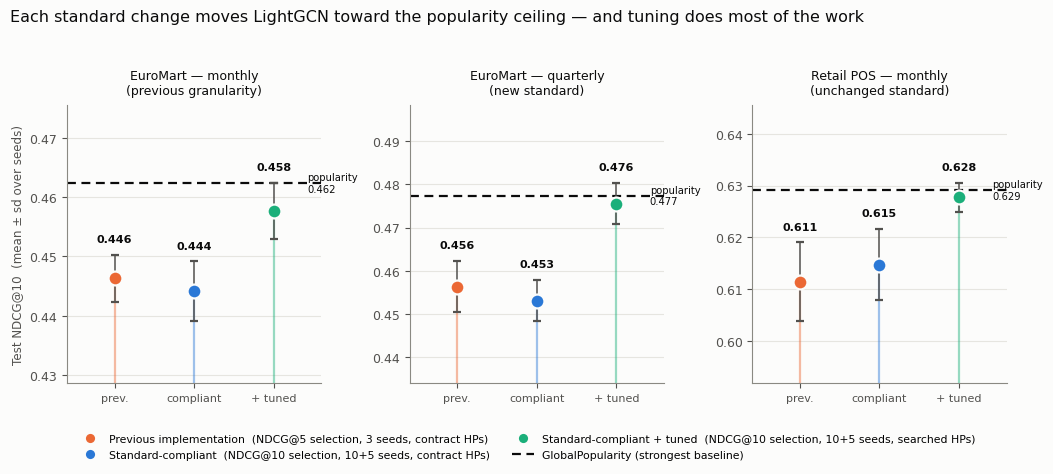

In [31]:
# test NDCG@10 by protocol
arms=[("LightGCN-Legacy@5-3seed","Previous implementation  (NDCG@5 selection, 3 seeds, contract HPs)",S2),
      ("LightGCN-Controlled","Standard-compliant  (NDCG@10 selection, 10+5 seeds, contract HPs)",S1),
      ("LightGCN-Tuned","Standard-compliant + tuned  (NDCG@10 selection, 10+5 seeds, searched HPs)",S3)]
fig,axes=plt.subplots(1,3,figsize=(10.6,3.9))
for ax,d in zip(axes,DS):
    vals=[mean(d,m) for m,_,_ in arms]
    lo=min([v-e for v,e in vals]+[pop(d)]); hi=max([v+e for v,e in vals]+[pop(d)])
    pad=(hi-lo)*0.45 or 0.01
    ax.axhline(pop(d),color=INK,ls=(0,(4,2.5)),lw=1.6,zorder=2)
    ax.text(2.42,pop(d),f"popularity\n{pop(d):.3f}",va="center",ha="left",fontsize=7.2,color=INK)
    for i,((m,lab,col),(v,e)) in enumerate(zip(arms,vals)):
        ax.vlines(i,lo-pad,v,color=col,lw=1.6,alpha=0.45,zorder=3)
        ax.errorbar([i],[v],yerr=[e],fmt="o",ms=10,color=col,mec=SURF,mew=1.6,
                    ecolor=INK2,elinewidth=1.1,capsize=3,zorder=4)
        ax.text(i,v+e+(hi-lo)*0.09,f"{v:.3f}",ha="center",fontsize=8,color=INK,fontweight="bold")
    ax.set_xlim(-0.6,2.6); ax.set_ylim(lo-pad,hi+pad*1.25)
    ax.set_xticks([0,1,2]); ax.set_xticklabels(["prev.","compliant","+ tuned"],fontsize=8)
    ax.grid(axis="y",color=GRID,lw=0.8); ax.set_axisbelow(True)
    ax.set_title(TTL[d],fontsize=9,color=INK,pad=8)
axes[0].set_ylabel("Test NDCG@10  (mean ± sd over seeds)",fontsize=8.6)
fig.suptitle("Each standard change moves LightGCN toward the popularity ceiling — and tuning does most of the work",
             fontsize=11.5,color=INK,x=0.012,ha="left",y=1.045)
fig.legend(handles=[Line2D([0],[0],marker="o",ls="",ms=8,color=c,mec=SURF,mew=1.4) for _,_,c in arms]
           +[Line2D([0],[0],color=INK,ls=(0,(4,2.5)),lw=1.6)],
           labels=[l for _,l,_ in arms]+["GlobalPopularity (strongest baseline)"],
           fontsize=7.8,frameon=False,loc="upper center",bbox_to_anchor=(0.5,-0.02),ncol=2)
fig.tight_layout(); fig.savefig(FIG/"Figure17_change_impact.png",dpi=190,bbox_inches="tight"); plt.show()


**Gap to GlobalPopularity.** Difference in test NDCG@10 with 95% bootstrap intervals, earlier protocol vs final.

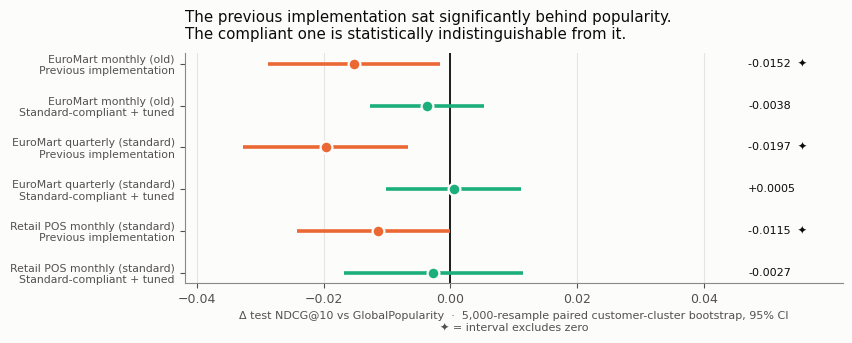

In [32]:
# gap to popularity with bootstrap intervals
fig,ax=plt.subplots(figsize=(8.6,3.5))
rows=[]
for d in DS:
    for m,lab,col in [("LightGCN-Legacy@5-3seed","Previous implementation",S2),
                      ("LightGCN-Tuned","Standard-compliant + tuned",S3)]:
        r=bt[(bt.dataset==d)&(bt.model==m)&(bt.baseline=="GlobalPopularity")].iloc[0]
        rows.append((SHORT[d],lab,col,r.delta_NDCG10,r.ci10_lo,r.ci10_hi))
y=np.arange(len(rows))[::-1]
for yi,(ds_,lab,col,dd,lo,hi) in zip(y,rows):
    ax.hlines(yi,lo,hi,color=col,lw=2.6,zorder=3)
    ax.plot([dd],[yi],"o",ms=8.5,color=col,mec=SURF,mew=1.6,zorder=4)
    ax.text(0.047,yi,f"{dd:+.4f}"+("" if lo<0<hi else "  ✦"),va="center",fontsize=8,color=INK)
ax.axvline(0,color=INK,lw=1.3,zorder=2)
ax.set_yticks(y); ax.set_yticklabels([f"{a}\n{bb}" for a,bb,_,_,_,_ in rows],fontsize=7.8)
ax.set_xlim(-0.042,0.062); ax.set_xticks(np.arange(-0.04,0.045,0.02))
ax.grid(axis="x",color=GRID,lw=0.8); ax.set_axisbelow(True)
ax.set_xlabel("Δ test NDCG@10 vs GlobalPopularity  ·  5,000-resample paired customer-cluster bootstrap, 95% CI"
              "\n✦ = interval excludes zero",fontsize=8)
ax.set_title("The previous implementation sat significantly behind popularity.\nThe compliant one is statistically indistinguishable from it.",
             fontsize=10.8,color=INK,pad=10,loc="left")
fig.tight_layout(); fig.savefig(FIG/"Figure18_delta_forest.png",dpi=190,bbox_inches="tight"); plt.show()


**Correlation with popularity.** Spearman correlation between scores and popularity by depth K (left), and test NDCG@10 against that correlation (right).

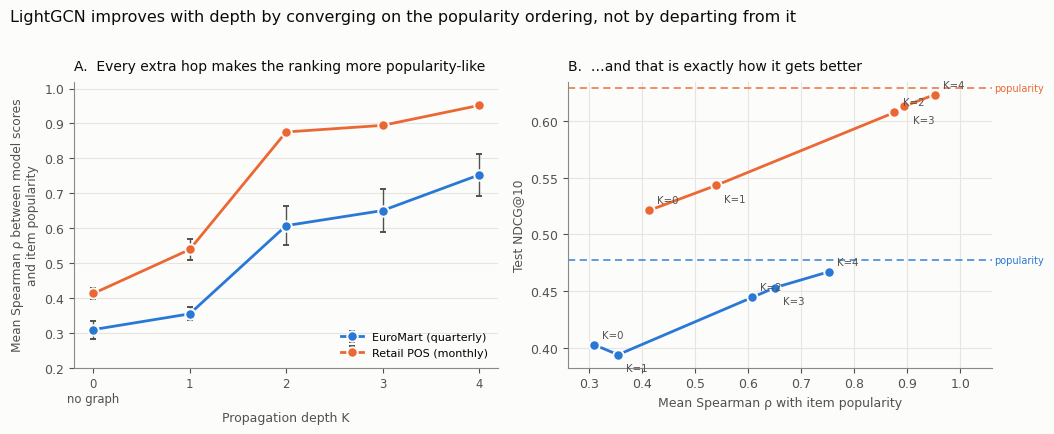

In [33]:
# correlation with popularity by depth
def ndcg(ds,K):
    m="LightGCN-NoMessages" if K==0 else f"LightGCN-Depth{K}"
    s=f[(f.dataset==ds)&(f.method==m)]; return s["NDCG@10"].mean()
def pop(ds): return b[(b.dataset==ds)&(b.method=="GlobalPopularity")]["NDCG@10"].iloc[0]
DS=[("euromart_quarterly","EuroMart (quarterly)",S1),("retail_pos_monthly","Retail POS (monthly)",S2)]

fig,axes=plt.subplots(1,2,figsize=(10.6,4.2))
ax=axes[0]
for ds,lab,c in DS:
    r=rho[rho.dataset==ds].sort_values("K")
    ax.errorbar(r.K,r.rho_pop_mean,yerr=r.rho_pop_sd,fmt="-o",color=c,lw=2,ms=7.5,
                mec=SURF,mew=1.4,ecolor=INK2,elinewidth=1,capsize=2.5,label=lab,zorder=3)
ax.set_xticks([0,1,2,3,4]); ax.set_xticklabels(["0\nno graph","1","2","3","4"],fontsize=8.4)
ax.set_xlabel("Propagation depth K",fontsize=9)
ax.set_ylabel("Mean Spearman ρ between model scores\nand item popularity",fontsize=8.8)
ax.set_ylim(0.2,1.02); ax.grid(axis="y",color=GRID,lw=0.8); ax.set_axisbelow(True)
ax.legend(fontsize=8,frameon=False,loc="lower right")
ax.set_title("A.  Every extra hop makes the ranking more popularity-like",fontsize=10,color=INK,pad=8,loc="left")

ax=axes[1]
for ds,lab,c in DS:
    r=rho[rho.dataset==ds].sort_values("K")
    x=r.rho_pop_mean.values; y=[ndcg(ds,int(k)) for k in r.K]
    ax.plot(x,y,"-o",color=c,lw=2,ms=7.5,mec=SURF,mew=1.4,label=lab,zorder=3)
    for n,(xi,yi,k) in enumerate(zip(x,y,r.K)):
        off=(6,5) if n%2==0 else (6,-12)
        ax.annotate(f"K={int(k)}",xy=(xi,yi),xytext=off,textcoords="offset points",
                    fontsize=7.3,color=INK2)
    ax.axhline(pop(ds),color=c,ls=(0,(4,2.5)),lw=1.3,alpha=0.8,zorder=2)
    ax.text(1.005,pop(ds),"popularity",fontsize=7,color=c,va="center",
            transform=ax.get_yaxis_transform(),clip_on=False)
ax.set_xlabel("Mean Spearman ρ with item popularity",fontsize=9)
ax.set_ylabel("Test NDCG@10",fontsize=8.8)
ax.grid(color=GRID,lw=0.8); ax.set_axisbelow(True); ax.set_xlim(0.26,1.06)
ax.set_title("B.  …and that is exactly how it gets better",fontsize=10,color=INK,pad=8,loc="left")
fig.suptitle("LightGCN improves with depth by converging on the popularity ordering, not by departing from it",
             fontsize=11.5,color=INK,x=0.012,ha="left",y=1.02)
fig.tight_layout(); fig.savefig(FIG/"Figure19_and_29_rho_pop.png",dpi=190,bbox_inches="tight"); plt.show()


## 13. Conclusion
Tuned LightGCN is level with popularity on both datasets. It gets there through node degree rather than through who bought what: rewiring does not hurt, and the correlation with popularity rises with K. With 17 densely connected categories this is not surprising. Notebook 13 checks what happens with larger catalogues.